# Pesos, remuestreo y ensembles en ambas ramas

Se evalúan pesos, remuestreo y ensembles antes de congelar modelos y evaluar el test.

## Inicialización

Usamos la misma identidad de datos, código y protocolo en todos los cuadernos.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)
ROOT = Path.cwd()
while not (ROOT/'scripts/mlcore').is_dir():
    if ROOT == ROOT.parent: raise RuntimeError('No se encontro la raiz del proyecto')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'scripts'))
from mlcore.experiment import initialize, aligned
from mlcore.data import read_data, FOLDS, TEST
OUT = initialize()
print('Ejecucion verificada:', OUT.name)


Ejecucion verificada: 39622169225decc0


**Qué encontramos y cómo se usa.** La identidad evita mezclar artefactos de protocolos distintos. Los cálculos científicos viven en `scripts/mlcore`; estos cuadernos explican, ejecutan y muestran cada etapa.

## Predicciones previas para ensembles

Los pesos y el stacking usan temporadas anteriores; 2017/18 inicializa el primer fold. No hay un método de respaldo distinto en 2018/19.

In [2]:
from mlcore.experiment import feedback
if not (OUT/'oof_candidates.csv').exists(): feedback(OUT)
display(pd.read_csv(OUT/'ensemble_weights.csv'))
results=pd.read_csv(OUT/'model_comparison.csv')
display(results[results.candidate.str.contains('mean|weighted|stack')])

,branch,season,con/LR_REF,con/LR_consenso,con/LR,con/HGB,con/XGB,con/RF,con/MLP,con/SVM,sin/LR_historia,sin/LR_plantilla,sin/LR,sin/HGB,sin/XGB,sin/RF,sin/MLP,sin/SVM
0,con,1819,0.905569,0.000000e+00,0.057212,0.000000e+00,3.325451e-18,4.714924e-17,0.000000e+00,3.721971e-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,con,1920,0.982955,0.000000e+00,0.017045,4.647196e-18,1.455255e-18,2.410330e-17,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,con,2021,0.940908,0.000000e+00,0.059092,0.000000e+00,3.371554e-17,0.000000e+00,0.000000e+00,1.041264e-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,con,2122,0.905969,1.289997e-16,0.082208,0.000000e+00,0.000000e+00,0.000000e+00,1.537534e-17,1.182306e-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,con,2223,0.907429,5.199431e-17,0.092571,0.000000e+00,0.000000e+00,0.000000e+00,1.732445e-18,3.973748e-17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,con,2324,0.911339,1.087455e-16,0.084624,1.160096e-17,0.000000e+00,2.938188e-17,0.000000e+00,4.036712e-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,sin,1819,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.102404,0.316617,0.000000e+00,0.046288,0.000000,0.302293,0.232399,2.398605e-17
7,sin,1920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.216317,0.213251,4.135519e-17,0.058662,0.110957,0.099997,0.300815,0.000000e+00
8,sin,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.228733,0.213478,1.986334e-18,0.174907,0.061660,0.077087,0.244136,0.000000e+00
9,sin,2122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.214492,0.201087,5.728969e-17,0.176239,0.139851,0.000000,0.267898,4.330150e-04


,candidate,n,log_loss,RPS,Brier,AUC_macro,accuracy,balanced_accuracy,ECE_masa,ECE_ancho,acierto_ganador_condicional,recall_empate
1,con/weighted,18184,0.965218,0.194984,0.572874,0.684354,0.538440,0.464340,0.008883,0.006541,0.716502,0.001770
3,con/mean,18184,0.967337,0.195547,0.574265,0.681889,0.538165,0.463130,0.010523,0.009753,0.716209,0.000000
11,con/stack,18184,0.974321,0.196413,0.579289,0.678916,0.527387,0.466817,0.014715,0.012826,0.713209,0.088515
13,sin/weighted,18184,0.977394,0.198726,0.581160,0.671953,0.531016,0.454889,0.015247,0.013844,0.706623,0.000000
14,sin/mean,18184,0.977599,0.198801,0.581351,0.671613,0.531401,0.454404,0.015104,0.013440,0.707135,0.000000
32,sin/stack,18184,0.985126,0.200105,0.586216,0.667227,0.523262,0.460810,0.015087,0.012382,0.700988,0.070812


**Qué encontramos / decisión.** Ambos ensembles se evalúan en las mismas seis temporadas y consumen las configuraciones elegidas en cada fold.

## Pesos y remuestreo solicitados

Se prueban LR y HGB de ambas ramas. El entrenamiento ponderado según el mercado se etiqueta explícitamente.

In [3]:
display(pd.read_csv(OUT/'market_guided_results.csv'))
print('Recalibracion posterior:',pd.read_csv(OUT/'oof_recalibration.csv').candidate.unique().tolist())

,candidate,n,log_loss,RPS,Brier,AUC_macro,accuracy,balanced_accuracy,ECE_masa,ECE_ancho,acierto_ganador_condicional,recall_empate
0,con/LR/none,18184,0.965199,0.194988,0.572867,0.684391,0.538715,0.464498,0.008538,0.006877,0.716795,0.001992
1,con/LR/undersample,18184,0.967604,0.195678,0.574515,0.684603,0.536571,0.466064,0.021827,0.020917,0.715404,0.019252
2,con/LR/balance,18184,0.967633,0.195685,0.574534,0.684575,0.536571,0.466032,0.021868,0.020970,0.715185,0.019031
3,con/LR/oversample,18184,0.967653,0.195693,0.574517,0.684533,0.537505,0.467099,0.021286,0.020279,0.715477,0.020580
4,con/HGB/none,18184,0.968530,0.195704,0.574816,0.680613,0.538495,0.464325,0.012702,0.009617,0.716795,0.000000
5,con/HGB/oversample,18184,0.972193,0.196934,0.577504,0.680675,0.538220,0.464851,0.028487,0.023556,0.716502,0.001770
6,con/HGB/undersample,18184,0.972513,0.197016,0.577736,0.680383,0.536296,0.463264,0.027924,0.025161,0.714160,0.005753
7,con/HGB/balance,18184,0.972651,0.197032,0.577825,0.680016,0.536131,0.463670,0.028419,0.024520,0.713794,0.005311
8,sin/HGB/none,18184,0.979474,0.199331,0.582538,0.669827,0.528982,0.451883,0.013270,0.011538,0.703915,0.000000
9,sin/LR/none,18184,0.980137,0.199215,0.582520,0.669522,0.529037,0.453824,0.016032,0.015056,0.704135,0.000885


Recalibracion posterior: ['con/LR/balance_recal', 'con/HGB/balance_recal', 'sin/LR/balance_recal', 'sin/HGB/balance_recal']


**Qué encontramos / decisión.** No se afirma que todas las variantes empeoren en cada temporada. El modelo sin cuotas puro no recibe estos pesos; son experimentos adicionales guiados por mercado.

## Congelar una selección por enfoque

Se elige menor log loss; dentro de 0,0005, se prefiere simplicidad. El test aún no se genera en esta etapa.

In [4]:
from mlcore.experiment import freeze
frozen=freeze(OUT)
print(json.dumps(frozen['selected'],indent=2,ensure_ascii=False))

{
  "con": {
    "candidate": "con/LR_REF",
    "spec": {
      "branch": "con",
      "name": "LR_REF",
      "family": "LR",
      "columns": [
        "REF_logit",
        "REF_pD"
      ],
      "reduction": "all"
    },
    "parameter": {
      "C": 0.05
    },
    "validation_log_loss": 0.965199124283032
  },
  "sin": {
    "candidate": "sin/mean",
    "spec": null,
    "parameter": null,
    "validation_log_loss": 0.9775994901181446
  }
}


**Qué encontramos / decisión.** La selección queda vinculada a huellas de predicciones y protocolo. Cambiarla exige una ejecución nueva.

## Recalibración de la variante balanceada

La variante que iguala el peso de aciertos y fallos del favorito se puede recalibrar con la temporada anterior. Comparamos antes y después en las cinco temporadas donde hay recalibración disponible. Estos pesos usan información del mercado.

In [5]:
from mlcore.metrics import metrics
df, sets = read_data(OUT); frame = df[df.Season.isin(FOLDS[1:])]
recal = pd.read_csv(OUT/'oof_recalibration.csv'); weighted = pd.read_csv(OUT/'oof_market_guided.csv'); rows = []
for name in recal.candidate.unique():
    ref = name.removesuffix('_recal').rsplit('/', 1)[0]+'/none'
    for label, source, candidate in [('sin pesos', weighted, ref), ('balance', weighted, name.removesuffix('_recal')), ('balance recalibrado', recal, name)]:
        rows.append(dict(modelo=name.rsplit('/', 1)[0], variante=label, **metrics(frame.y, aligned(source, candidate, frame))))
display(pd.DataFrame(rows)[['modelo', 'variante', 'log_loss', 'ECE_masa']].round(4))

,modelo,variante,log_loss,ECE_masa
0,con/LR,sin pesos,0.9665,0.0095
1,con/LR,balance,0.9690,0.0230
2,con/LR,balance recalibrado,0.9675,0.0088
3,con/HGB,sin pesos,0.9693,0.0135
4,con/HGB,balance,0.9738,0.0295
5,con/HGB,balance recalibrado,0.9701,0.0117
6,sin/LR,sin pesos,0.9810,0.0160
7,sin/LR,balance,0.9815,0.0157
8,sin/LR,balance recalibrado,0.9818,0.0114
9,sin/HGB,sin pesos,0.9804,0.0143


**Qué encontramos / decisión.** Recalibrar corrige la calibración de la variante balanceada (el ECE de la LR con cuotas baja de 0,023 a 0,009), pero su log loss sigue por encima del entrenamiento sin pesos en los cuatro casos. Los pesos no aportan nada que una recalibración pueda rescatar.

## Pesos del ensemble ponderado por temporada

El ensemble ponderado aprende, con las temporadas anteriores, cuánto peso dar a cada modelo. Vemos si esos pesos son estables.

con · peso medio: {'LR_REF': 0.93, 'LR_consenso': 0.0, 'LR': 0.07, 'HGB': 0.0, 'XGB': 0.0, 'RF': 0.0, 'MLP': 0.0, 'SVM': 0.01}
sin · peso medio: {'LR_historia': 0.21, 'LR_plantilla': 0.22, 'LR': 0.0, 'HGB': 0.11, 'XGB': 0.13, 'RF': 0.1, 'MLP': 0.23, 'SVM': 0.01}


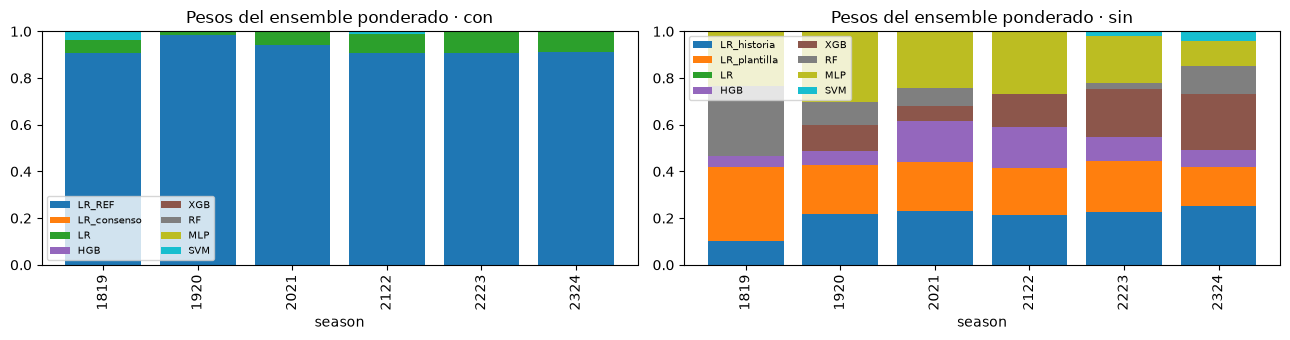

In [6]:
w = pd.read_csv(OUT/'ensemble_weights.csv'); fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, branch in zip(axes, ('con', 'sin')):
    t = w[w.branch.eq(branch)].set_index('season').drop(columns='branch').dropna(axis=1, how='all'); t.columns = [c.split('/')[1] for c in t.columns]
    t.plot.bar(stacked=True, ax=ax, width=.8, colormap='tab10'); ax.set_title('Pesos del ensemble ponderado · '+branch); ax.legend(fontsize=7, ncol=2); ax.set_ylim(0, 1)
    print(branch, '· peso medio:', t.mean().round(2).to_dict())
plt.tight_layout(); plt.show()

**Qué encontramos / decisión.** Con cuotas, el ponderado pone en promedio el 93 % del peso en la LR de solo precio y casi todo el resto en la LR completa: es casi un único modelo. Sin cuotas el peso se reparte entre las dos LR reducidas, la red neuronal y los árboles. La SVM casi no recibe peso en ninguno de los dos enfoques.

## Por qué promediar ayuda sin cuotas y no con cuotas

Promediar modelos sirve cuando son parecidos en calidad y se equivocan en partidos distintos. Medimos la correlación entre las pérdidas por partido de los miembros de cada ensemble.

In [7]:
from mlcore.metrics import losses
from mlcore.experiment import ensemble_member_names
va = df[df.Season.isin(FOLDS)]; base = pd.read_csv(OUT/'oof_base.csv')
for branch in ('con', 'sin'):
    miembros = ensemble_member_names(branch); L = pd.DataFrame({k.split('/')[1]: losses(va.y, aligned(base, k, va)) for k in miembros}); c = L.corr()
    fuera = c.where(~np.eye(len(c), dtype=bool)).stack(); media = losses(va.y, np.mean([aligned(base, k, va) for k in miembros], axis=0)).mean()
    print(f'{branch}: correlación media entre pérdidas {fuera.mean():.3f} (mínima {fuera.min():.3f}) | mejor miembro {L.mean().idxmin()} = {L.mean().min():.4f} | peor {L.mean().idxmax()} = {L.mean().max():.4f} | promedio simple = {media:.4f}')
    display(L.mean().sort_values().round(4).rename('log loss de cada miembro').to_frame().T)

con: correlación media entre pérdidas 0.960 (mínima 0.886) | mejor miembro LR_REF = 0.9652 | peor SVM = 0.9945 | promedio simple = 0.9673


,LR_REF,LR_consenso,RF,XGB,HGB,LR,MLP,SVM
log loss de cada miembro,0.9652,0.9657,0.9676,0.9683,0.9685,0.9699,0.9723,0.9945


sin: correlación media entre pérdidas 0.964 (mínima 0.895) | mejor miembro LR_plantilla = 0.9787 | peor SVM = 0.9960 | promedio simple = 0.9776


,LR_plantilla,XGB,RF,HGB,MLP,LR_historia,LR,SVM
log loss de cada miembro,0.9787,0.9787,0.9794,0.9795,0.9795,0.9798,0.9801,0.996


**Qué encontramos / decisión.** La correlación entre las pérdidas de los miembros es igual de alta en ambos enfoques (0,96), así que esa no es la diferencia. Lo que cambia es la calidad relativa: con cuotas hay un miembro claramente mejor (0,9652) y promediarlo con otros peores lo empeora (0,9673); sin cuotas siete miembros están entre 0,9787 y 0,9801 y su promedio (0,9776) mejora al mejor de ellos.

## Pesos a los partidos sorpresivos, temporada por temporada

El resultado agregado dice que dar más peso a las sorpresas empeora. Comprobamos si eso pasa en todas las temporadas o solo en el total.

In [8]:
from sklearn.metrics import log_loss
rows = []
for cand in sorted(weighted.candidate.unique()):
    branch, family, scheme = cand.split('/')
    if scheme == 'none': continue
    for s in FOLDS:
        f = va[va.Season.eq(s)]
        rows.append(dict(modelo=branch+'/'+family, esquema=scheme, temporada=s,
                         delta=log_loss(f.y, aligned(weighted, cand, f), labels=[0, 1, 2])-log_loss(f.y, aligned(weighted, f'{branch}/{family}/none', f), labels=[0, 1, 2])))
t = pd.DataFrame(rows); display(t.pivot_table(index=['modelo', 'esquema'], columns='temporada', values='delta').round(4))
print('Combinaciones modelo/esquema/temporada que mejoran al entrenamiento sin pesos:', int((t.delta < 0).sum()), 'de', len(t))
display(t[t.delta < 0].round(5))

temporada               1819    1920    2021    2122    2223    2324
modelo  esquema                                                     
con/HGB balance       0.0024  0.0029  0.0026  0.0040  0.0062  0.0066
        inverse       0.1037  0.1017  0.0922  0.1134  0.1188  0.1307
        oversample    0.0019  0.0036  0.0009  0.0037  0.0049  0.0070
        sqrt_inverse  0.0267  0.0251  0.0227  0.0309  0.0334  0.0380
        undersample   0.0022  0.0033  0.0021  0.0040  0.0060  0.0061
        w2            0.0422  0.0442  0.0442  0.0491  0.0606  0.0595
        w3            0.1125  0.1114  0.1125  0.1217  0.1403  0.1407
        w5            0.2419  0.2405  0.2390  0.2532  0.2822  0.2827
con/LR  balance       0.0018  0.0012  0.0012  0.0023  0.0042  0.0038
        inverse       0.1073  0.0994  0.0932  0.1104  0.1189  0.1292
        oversample    0.0015  0.0012  0.0015  0.0022  0.0041  0.0041
        sqrt_inverse  0.0239  0.0208  0.0199  0.0265  0.0313  0.0356
        undersample   0.0018  0.0012  0.0011  0.0023  0.0041  0.0037
        w2            0.0383  0.0346  0.0343  0.0409  0.0489  0.0462
        w3            0.0977  0.0896  0.0882  0.0996  0.1103  0.1075
        w5            0.2113  0.1948  0.1909  0.2095  0.2214  0.2211
sin/HGB balance       0.0011  0.0015 -0.0008  0.0012  0.0045  0.0012
        inverse       0.0931  0.0883  0.0784  0.0989  0.1157  0.1154
        oversample    0.0008  0.0006 -0.0024  0.0017  0.0030  0.0012
        sqrt_inverse  0.0208  0.0186  0.0140  0.0231  0.0307  0.0296
        undersample   0.0010  0.0009 -0.0011  0.0014  0.0043  0.0016
        w2            0.0351  0.0334  0.0266  0.0387  0.0505  0.0438
        w3            0.0882  0.0839  0.0742  0.0933  0.1117  0.1080
        w5            0.1909  0.1853  0.1680  0.1963  0.2209  0.2198
sin/LR  balance      -0.0003 -0.0010 -0.0025  0.0008  0.0029  0.0022
        inverse       0.0954  0.0852  0.0796  0.1013  0.1166  0.1229
        oversample    0.0008 -0.0005 -0.0014  0.0011  0.0026  0.0031
        sqrt_inverse  0.0173  0.0124  0.0099  0.0207  0.0277  0.0305
        undersample  -0.0003 -0.0010 -0.0025  0.0009  0.0031  0.0023
        w2            0.0301  0.0269  0.0213  0.0354  0.0453  0.0420
        w3            0.0858  0.0798  0.0713  0.0923  0.1076  0.1036
        w5            0.1937  0.1828  0.1701  0.1988  0.2209  0.2177

Combinaciones modelo/esquema/temporada que mejoran al entrenamiento sin pesos: 11 de 192


,modelo,esquema,temporada,delta
98,sin/HGB,balance,2021,-0.00078
110,sin/HGB,oversample,2021,-0.00239
122,sin/HGB,undersample,2021,-0.00106
144,sin/LR,balance,1819,-0.00032
145,sin/LR,balance,1920,-0.00097
146,sin/LR,balance,2021,-0.00253
157,sin/LR,oversample,1920,-0.00050
158,sin/LR,oversample,2021,-0.00137
168,sin/LR,undersample,1819,-0.00026
169,sin/LR,undersample,1920,-0.00103


**Qué encontramos / decisión.** Con cuotas, todos los esquemas empeoran en las seis temporadas. Sin cuotas hay 11 combinaciones de 192 con una mejora pequeña (como mucho 0,0025), siempre con los esquemas suaves (balance y remuestreo) y entre 2018/19 y 2020/21. Los pesos fijos 2, 3 y 5 y los inversos empeoran siempre. En el agregado ninguna variante mejora al entrenamiento sin pesos. Estas variantes usan el mercado para definir los pesos, así que no forman parte del modelo deportivo puro.